# 배치 789 수율 일탈 정밀 분석 — 무엇이, 언제, 얼마나

제품 17 · 배치 789 · 수율 **87.97%** (제품 기준선 98.77%, robust z = −15.4). 이 데이터 1,005개 배치 중 가장 큰 수율 저하입니다.

배치별 RCA 노트북(`rca_batches/RCA_product17_batch789.ipynb`)은 14개 6M 가설을 같은 틀로 검정해 "재시작 후 안정화 확인 절차 부재(RC-MAC)", "운전 설정값 이중 확인 절차 부재(RC-MAN-B)"로 결론 냈습니다. 틀린 말은 아니지만 **어느 배치에나 붙일 수 있는 일반론**입니다. 이 노트북은 틀을 버리고 789의 데이터 전체를 처음부터 다시 봅니다.

**질문** : 789에서 *무엇이* 평소와 달랐고, 손실이 *언제·어디서* 몇 정씩 생겼으며, 그중 *무엇이 원인이고 무엇이 결과*인가?

**근거 표시**
- **[확인]** 데이터에서 직접 계산되는 사실 (검정 불필요)
- **[통계]** 검정으로 지지되는 주장 (방법·p값 표시)
- **[추정]** 데이터와 맞지만 데이터만으로는 확정할 수 없는 해석 → 확인할 기록을 함께 적음

## 결론 요약

| # | 발견 | 근거 | 손실 영향 |
|---|---|---|---|
| 1 | 789는 같은 제품 784·785와 **같은 시간에** 생산됐다 → 평소와 **다른 타정기(2호기)**에서 만들어졌다 | [확인] 타임스탬프 겹침 63분·314분. 제품 17의 207개 배치 중 같은 제품끼리 시간이 겹친 경우는 이 두 쌍뿐 | 전제 |
| 2 | 운전 조건이 제품 17 이력 **범위 밖** : 타정 속도 200→250→300(이력 최대 160), 주압축력 17.6 kN(이력 최대 8.6), 셋업 0.5분(이력 최소 21.7분). 원료 물성은 모두 평소 범위 | [확인] 이력 최소·최대 비교 · [통계] 경험적 p, BH 보정 | 전제 |
| 3 | 기록된 폐기 43,707정의 **93%(40,551정)는 정지 후 재시작한 짧은 운전 6번**에서 나왔다. 이 운전들은 첫 샘플부터 생산량 전부가 폐기로 빠졌고 0.3~3.8분 만에 다시 멈췄다. 정지 한 번에 따라온 폐기는 8건 모두 평소 정지의 상위 8% 안(5건은 상위 1%) | [확인] 10초 시계열 · [통계] 맨-휘트니 U | **−40,551정 (−4.2%p)** |
| 4 | 전량 폐기 운전과 양품 운전 사이에 압축력·충전 깊이·무게 신호(SREL) 차이가 없다 → 폐기는 품질 신호가 아니라 **운전 방식(재시작 직후 배출 전환)**에서 나왔다 | [통계] 운전 단위 정확 순열검정 | 기전 |
| 5 | 마지막 111분은 속도 300에서 폐기 없이 돌았다 → **고속 자체가 기록된 폐기의 원인은 아니다** | [확인] | — |
| 6 | 960,000정 중 **67,293정은 양품 계수기에도 폐기 계수기에도 잡히지 않았다** (참조 최대 12,940정의 5배). 제품 17 이력에서 속도 160 배치는 120 배치보다 미계수 손실이 약 3배 → **고속과 미계수 손실이 함께 움직인다** | [확인] 질량 수지 · [통계] 맨-휘트니 U, 스피어만 ρ · 구체 경로는 [추정] | **−67,293정 (−7.0%p)** |
| 7 | 높은 배출력(563)은 높은 압축력으로 설명된다 (이력 회귀 예측 560, 95% 예측구간 안) → 독립 원인이 아니라 결과 | [통계] 회귀 예측구간 | — |
| 8 | API 로트 197을 쓴 배치는 789와 제품 15의 799 두 개뿐이고 **둘 다 수율 일탈** — 로트 물성은 평범 | [통계] Fisher 정확검정 p = 0.008 · 기전은 미확인 | 추가 확인 |

**한 문장 결론** : 789의 손실은 "기준이 없어서"가 아니라, **평소와 다른 타정기에서 검증된 적 없는 고속·고압 조건으로 셋업 없이 시작한 뒤, 생산 도중 속도를 200→250→300으로 올리면서 정지·재시작마다 생산 속도로 전량 폐기 운전을 6번 반복(4.1만 정)했고, 그와 별개로 6.7만 정이 계수되지 않은 채 사라진 것**입니다. 두 손실을 참조 수준으로 되돌리면 수율은 약 98.4%로 정상 범위입니다.

## 0. 준비

- 데이터 : `data/` 의 Laboratory·Process(배치 요약)·Process.zip(10초 시계열)
- 참조군 : **제품 17의 다른 206개 배치** (같은 제품·같은 규격)
- 데이터 정리(배치 지표·손실 분해·날짜 보정)는 `rca_batches/rca_core.py` 를 쓰고, 분석·검정은 이 노트북에서 직접 함

In [1]:
import sys
sys.path.insert(0, "rca_batches")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.covariance import MinCovDet
from IPython.display import display, Markdown

from rca_core import RCA, load_base, load_product_ts, resolve_dates, find_data_dir, judged, spec_table, _segments

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

DATA = str(find_data_dir())
B, CODE = 789, 17
ctx = RCA(B)                         # 제품 17 배치 지표·손실 분해 (rca_core)
dp, T, ref = ctx.dp, ctx.T, ctx.ref  # 제품 전체 / 대상 배치 / 참조 배치(대상 제외)
df, NORM = load_base(DATA)
ts = load_product_ts(DATA, CODE)
dates = resolve_dates(DATA, CODE)
spec = spec_table(DATA)
print(f"참조 배치 {len(ref)}개 · 789 수율 {T.batch_yield:.2f}% · 기준선 {spec.loc[CODE, '기준선']:.2f}% · 일탈 하한 {spec.loc[CODE, '일탈_하한']:.2f}%")

참조 배치 206개 · 789 수율 87.97% · 기준선 98.77% · 일탈 하한 96.67%


### 사용하는 검정과 쓰는 이유

대상이 배치 **하나**라서 "두 집단 비교" 검정을 789에 바로 쓸 수 없습니다. 질문마다 논리적으로 맞는 방법을 골랐습니다.

| 질문 | 방법 | 왜 이 방법인가 |
|---|---|---|
| 789의 값이 참조 분포에서 얼마나 극단인가 | **경험적 p** (참조 중 789만큼 극단인 비율, 양측) + **robust z** (중앙값·MAD) | 분포 가정 없이 n=1을 참조 분포 위에 놓는 가장 직접적인 방법. 참조가 206개라 최소 p ≈ 0.0097 |
| 수십 개 변수를 한꺼번에 볼 때 우연한 극단 | **Benjamini–Hochberg FDR** | 변수 약 80개를 동시에 보므로 다중 비교 보정 |
| 운전 조건 전체가 이례적인가 | **MCD 로버스트 마할라노비스 거리** | 변수 사이 상관을 고려한 다변량 이례성, 이상치에 강한 공분산 추정 |
| 789가 다른 배치와 같은 시간에 돌았나 | 타임스탬프 구간 겹침 (결정론) | 검정이 아니라 사실 확인 |
| 배치 안에서 폐기가 언제 생겼나 | 10초 시계열에서 **폐기 계수기 증가분 ÷ 같은 시간 생산 능력** | 폐기가 '일부 불량'인지 '전량 배출 전환'인지 구분 |
| 전량 폐기 운전과 양품 운전의 공정 신호 차이 | **운전 단위 정확 순열검정** (9개 운전의 가능한 모든 배치 84가지) | 10초 샘플은 서로 독립이 아님(자기상관) → 운전 하나를 단위로 묶고 정확한 귀무분포 사용 |
| 789의 정지 한 번당 폐기가 평소보다 큰가 | **맨-휘트니 U** (정지 단위) + 참조 분위수 | 정지 사건 단위 두 집단 비교, 분포 가정 없음 |
| 정지 횟수가 많은가 | **경험적 p** (포아송 p는 참고) | 배치별 정지 횟수는 과분산이라 포아송 가정이 p를 과소평가 |
| 배출력이 독립 원인인가, 압축력의 결과인가 | 참조 배치 **선형 회귀 예측구간** | 789의 배출력이 압축력만으로 예측되는 범위 안이면 독립 원인 근거 없음 |
| 고속이 수율·미계수 손실을 늘리나 | 속도 120 vs 160 배치 **맨-휘트니 U + 클리프 δ**, **스피어만 ρ** | 이력 안에서 가능한 비교 (300은 외삽 불가) |
| API 로트 197이 문제인가 | **Fisher 정확검정** (로트 197 여부 × 저수율 여부) | 2×2 소표본, 정확 검정 |
| 원인을 없애면 수율은 | **반사실 산술** (손실 구성 요소를 참조 중앙값으로 대체) | 손실 귀속 크기 비교 |

In [2]:
def emp_p(x, v):
    """양측 경험적 p : 참조 분포에서 v만큼(또는 더) 극단인 비율 × 2 (상한 1)"""
    x = pd.Series(x).dropna()
    lo = ((x <= v).sum() + 1) / (len(x) + 1)
    hi = ((x >= v).sum() + 1) / (len(x) + 1)
    return min(1.0, 2 * min(lo, hi))


def robust_z(x, v):
    x = pd.Series(x).dropna()
    s = 1.4826 * (x - x.median()).abs().median()
    return (v - x.median()) / s if s > 0 else np.nan


def bh(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1)
    return out


def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return (np.sign(a[:, None] - b[None, :])).mean()


def clock(minutes):
    return (dates.loc[B, "start_dt"] + pd.Timedelta(minutes=float(minutes))).strftime("%H:%M")

---
## 1. 얼마나 이례적인가 — 모든 변수 스크리닝

배치 요약 변수 전체(원료 물성·운전 설정·손실·품질)를 참조 206개 배치와 비교합니다. 789의 값이 참조 **최소~최대 범위 밖**인지, 경험적 p와 BH q는 얼마인지 봅니다.

In [3]:
SKIP = {"code", "campaign", "n_samples", "start_hour", "start_minute", "batch_yield", "tbl_yield", "loss_tab"}

def kind(v):
    if v.startswith(("api_", "lactose_", "smcc_", "starch_")): return "원료"
    if v.startswith(("tbl_speed", "main_Comp", "pre_Comp", "cyl_", "fom", "tbl_fill", "stiffness", "ejection", "SREL", "Startup_", "setting_dev", "early_fill")): return "운전"
    if v.startswith(("tbl_", "fct_", "dissolution", "impur", "resodual")): return "품질"
    return "손실·사건"

rows = []
for v in dp.select_dtypes("number").columns:
    if v in SKIP: continue
    x, t = ref[v].dropna(), T[v]
    if pd.isna(t) or len(x) < 30 or x.nunique() < 5: continue
    rows.append({"분류": kind(v), "변수": v, "789": t, "참조 중앙값": x.median(), "참조 최소": x.min(), "참조 최대": x.max(),
                 "범위 밖": not (x.min() <= t <= x.max()), "robust z": robust_z(x, t), "경험적 p": emp_p(x, t)})
SCR = pd.DataFrame(rows)
SCR["BH q"] = bh(SCR["경험적 p"])
print(f"변수 {len(SCR)}개 중 참조 범위 밖 {SCR['범위 밖'].sum()}개 · BH q < 0.05 {int((SCR['BH q'] < 0.05).sum())}개")
display(SCR.groupby("분류").agg(변수=("변수", "size"), 범위_밖=("범위 밖", "sum"), q_005=("BH q", lambda s: int((s < 0.05).sum()))))
with pd.option_context("display.float_format", "{:.3g}".format):
    display(SCR[SCR["범위 밖"] | (SCR["BH q"] < 0.05)].sort_values(["분류", "경험적 p"]).set_index(["분류", "변수"]))

변수 76개 중 참조 범위 밖 16개 · BH q < 0.05 16개


,변수,범위_밖,q_005
분류,,,
손실·사건,12,7,7
운전,26,9,9
원료,20,0,0
품질,18,0,0


789   참조 중앙값     참조 최소    참조 최대  범위 밖  robust z   경험적 p   BH q
분류    변수                                                                                             
손실·사건 total_waste                 4.55e+03      678       114 3.24e+03  True      8.49 0.00966 0.0459
      startup_waste                     78 5.16e+03  1.08e+03 1.99e+04  True     -1.59 0.00966 0.0459
      setup_min                        0.5     48.2      21.7      469  True     -3.16 0.00966 0.0459
      setup_idle_min                 0.167     44.2        20      466  True     -3.24 0.00966 0.0459
      w_setup                           78 5.16e+03  1.08e+03 1.99e+04  True     -1.59 0.00966 0.0459
      w_prod                      4.36e+04      137         4 2.31e+04  True       267 0.00966 0.0459
      w_unrec                     7.18e+04 3.89e+03 -3.74e+03 1.94e+04  True      31.2 0.00966 0.0459
운전    tbl_speed_mean                   272      120        90      160  True   3.5e+03 0.00966 0.0459
      fom_change                         3       10         4       43  True     -1.57 0.00966 0.0459
      SREL_startup_mean                1.4     5.79      2.48     24.5  True      -1.9 0.00966 0.0459
      main_CompForce mean             17.6     6.56      4.45     8.56  True      14.9 0.00966 0.0459
      main_CompForce_median           17.7      6.6       4.5      8.6  True        15 0.00966 0.0459
      ejection_mean                    563      187      3.65      483  True      14.5 0.00966 0.0459
      ejection_max                     694      221         8      549  True      10.6 0.00966 0.0459
      Startup_main_CompForce_mean     17.6     6.58       4.1     10.3  True      12.6 0.00966 0.0459
      setting_dev                      169     12.1    0.0112     33.4  True      11.8 0.00966 0.0459

**읽는 법**
- **원료 변수는 하나도 걸리지 않습니다.** 789의 API·부형제 물성은 평소 범위 안입니다.
- 걸린 것은 **운전**과 **손실·사건** 변수입니다. 특히 타정 속도·주압축력·셋업 시간·배출력은 참조 206개의 **최소~최대 범위를 아예 벗어납니다**.
- 품질 변수(경도·두께·용출 등)는 BH 보정 후 유의한 것이 없습니다. 용출은 8장에서 따로 봅니다.

In [4]:
# 다변량 : 핵심 운전 설정 4개의 로버스트 마할라노비스 거리
SET = ["tbl_speed_mean", "main_CompForce mean", "cyl_height_mean", "tbl_fill_mean"]
X = dp[SET].dropna()
mcd = MinCovDet(random_state=0).fit(X.drop(B))
d2 = pd.Series(mcd.mahalanobis(X), index=X.index)
print(f"789의 로버스트 거리² = {d2[B]:,.0f}  ·  참조 배치 최대 {d2.drop(B).max():,.0f}  ·  참조 중앙값 {d2.drop(B).median():.1f}")
print(f"χ²(4) 기준 p = {stats.chi2.sf(d2[B], len(SET)):.1e}")

789의 로버스트 거리² = 26,084,456  ·  참조 배치 최대 1,817,785  ·  참조 중앙값 5.1
χ²(4) 기준 p = 0.0e+00


**[통계]** 운전 설정 조합으로 봐도 789는 다른 모든 배치와 차원이 다른 거리에 있습니다. 이후 장에서는 *왜* 이런 조건이 나왔는지(2장), 그 조건에서 손실이 *어떻게* 생겼는지(4~5장)를 봅니다.

---
## 2. 언제·어디서 생산됐나 — 같은 제품 배치와 시간이 겹친다

배치 번호로는 789가 캠페인 155의 마지막(783~789 중 7번째)이지만, 시계열 타임스탬프로는 다릅니다.

In [5]:
c155 = [783, 784, 785, 786, 787, 788, 789]
camp = dates.loc[c155, ["start_dt", "end_dt"]].join(
    df.loc[c155, ["tbl_speed_mean", "main_CompForce mean", "cyl_height_mean", "startup_waste", "batch_yield"]])
raw = ts.groupby("batch").timestamp.agg(["first", "last"]).loc[c155]
camp = camp.join(raw.rename(columns={"first": "원본 시작", "last": "원본 종료"})).sort_values("start_dt")
display(camp.round({"tbl_speed_mean": 2, "main_CompForce mean": 2, "cyl_height_mean": 2, "batch_yield": 2}))

,start_dt,end_dt,tbl_speed_mean,main_CompForce mean,cyl_height_mean,startup_waste,batch_yield,원본 시작,원본 종료
783,2020-10-26 20:58:00,2020-10-27 06:08:00,119.98,6.86,1.90,18255,97.49,26102020 20:58,27102020 06:08
784,2020-10-27 06:23:00,2020-10-27 15:04:00,119.94,6.36,1.94,7753,98.86,27102020 06:23,27102020 15:04
789,2020-10-27 14:01:00,2020-10-27 20:23:00,271.68,17.63,1.72,78,87.97,27102020 14:01,27102020 20:23
785,2020-10-27 15:09:00,2020-10-28 01:51:00,119.90,6.56,1.87,10980,97.73,27102020 15:09,28102020 01:51
786,2020-10-28 01:54:00,2020-10-28 10:39:00,119.96,6.76,1.87,3598,99.20,28102020 01:54,28102020 10:39
787,2020-10-28 10:49:00,2020-10-28 19:23:00,119.99,6.86,1.87,6086,99.67,28102020 10:49,28102020 19:23
788,2020-10-28 19:23:00,2020-10-29 04:02:00,119.97,6.96,1.81,2718,99.48,28102020 19:23,29102020 04:02


In [6]:
# 제품 17 전체 이력에서 '같은 제품 배치끼리 시간이 겹친' 경우
g = dates.sort_values("start_dt")
pairs = []
for (b1, r1), (b2, r2) in itertools.combinations(g.iterrows(), 2):
    ov = (min(r1.end_dt, r2.end_dt) - max(r1.start_dt, r2.start_dt)).total_seconds() / 60
    if ov > 5:
        pairs.append({"배치 A": b1, "배치 B": b2, "겹친 시간(분)": round(ov)})
print(f"제품 17 배치 {len(g)}개 중 같은 제품끼리 5분 넘게 겹친 쌍 : {len(pairs)}개")
display(pd.DataFrame(pairs))

제품 17 배치 207개 중 같은 제품끼리 5분 넘게 겹친 쌍 : 2개


,배치 A,배치 B,겹친 시간(분)
0,784,789,63
1,789,785,314


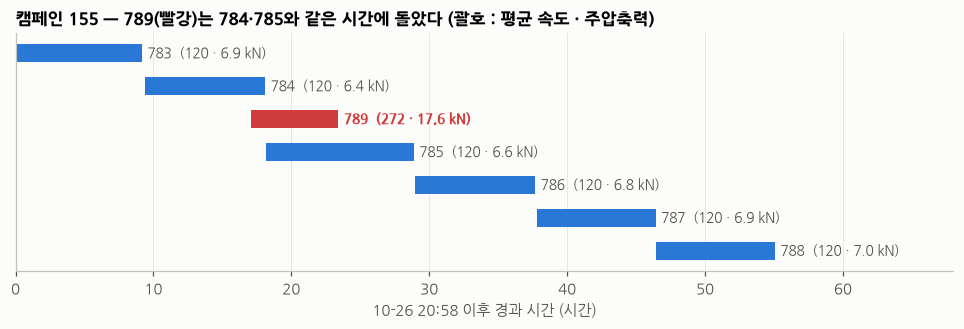

In [7]:
fig, ax = plt.subplots(figsize=(11, 2.8))
for i, (b, r) in enumerate(camp.iterrows()):
    is789 = b == B
    ax.barh(i, (r.end_dt - r.start_dt).total_seconds() / 3600, left=(r.start_dt - camp.start_dt.min()).total_seconds() / 3600,
            color="#d03b3b" if is789 else "#2a78d6", height=0.55)
    ax.text((r.end_dt - camp.start_dt.min()).total_seconds() / 3600 + 0.4, i, f"{b}  ({r.tbl_speed_mean:.0f} · {r['main_CompForce mean']:.1f} kN)",
            va="center", fontsize=9, color="#d03b3b" if is789 else "#52514e", fontweight="bold" if is789 else "normal")
ax.set_yticks([]); ax.invert_yaxis(); ax.set_xlim(0, 68)
ax.set_xlabel(f"{camp.start_dt.min():%m-%d %H:%M} 이후 경과 시간 (시간)")
ax.set_title("캠페인 155 — 789(빨강)는 784·785와 같은 시간에 돌았다 (괄호 : 평균 속도 · 주압축력)", loc="left", fontsize=11)
plt.show()

**[확인]** 789는 2020-10-27 14:01~20:23에 생산됐습니다. 같은 시간에 784(~15:04)와 785(15:09~)가 돌고 있었습니다. 원본 타임스탬프의 날짜가 27·28일이라 일·월 해석 문제도 없습니다.

한 타정기에서 두 배치를 동시에 찍을 수는 없으므로, **789는 평소 제품 17을 찍는 타정기와 다른 타정기(이하 '2호기')에서 생산됐습니다.** 제품 17의 207개 배치 중 같은 제품끼리 시간이 겹친 것은 이 두 쌍뿐이라, 2호기 생산은 이 데이터에서 **789 한 번**입니다.

- 데이터에 설비 번호가 없어 2호기가 어떤 기종인지는 알 수 없습니다 → **[추정]** 다음 장의 운전 조건(속도 300, 주압축력 17.6 kN)은 2호기의 능력·설정 체계 차이일 수 있습니다.
- 같은 캠페인 안 다른 배치는 셋업 폐기 2,700~18,000정을 냈지만 789는 78정입니다 (다음 장).

---
## 3. 어떤 조건으로 — 제품 17 이력 밖의 운전

789의 운전 조건을 제품 17의 다른 206개 배치 범위, 그리고 **25개 제품 전체 1,004개 배치** 범위와 비교합니다.

In [8]:
COND = {"tbl_speed_mean": "평균 타정 속도 (천 정/시간)", "main_CompForce mean": "평균 주압축력 (kN)",
        "Startup_main_CompForce_mean": "셋업 중 주압축력 (kN)", "cyl_height_mean": "주압축 실린더 높이",
        "ejection_mean": "평균 배출력", "setup_min": "셋업 시간 (분)", "startup_waste": "셋업 폐기 (정)",
        "prod_long_stops": "본생산 중 1분 이상 정지 (회)", "prod_stop_min": "본생산 중 정지 시간 (분)"}
others = df[df.index != B]
tab = []
for v, name in COND.items():
    src = dp if v in dp.columns else df[df.code == CODE]
    x = src.drop(B)[v]
    allx = others[v] if v in others.columns else None
    tab.append({"항목": name, "789": T[v] if v in T.index else df.loc[B, v], "제품 17 중앙값": x.median(),
                "제품 17 최소": x.min(), "제품 17 최대": x.max(),
                "전 제품 최대": allx.max() if allx is not None else np.nan,
                "경험적 p": emp_p(x, T[v] if v in T.index else df.loc[B, v])})
display(pd.DataFrame(tab).set_index("항목").round(3))
print("전 제품에서 평균 속도 200 이상 배치 :", list(df.index[df.tbl_speed_mean >= 200]),
      "· 주압축력 12 kN 이상 :", df[df["main_CompForce mean"] >= 12].code.to_dict())

,789,제품 17 중앙값,제품 17 최소,제품 17 최대,전 제품 최대,경험적 p
항목,,,,,,
평균 타정 속도 (천 정/시간),271.677,119.971,89.984,160.004,160.658,0.010
평균 주압축력 (kN),17.627,6.557,4.453,8.560,12.866,0.010
셋업 중 주압축력 (kN),17.650,6.582,4.104,10.255,13.022,0.010
주압축 실린더 높이,1.716,1.957,1.644,2.256,2.819,0.164
평균 배출력,563.192,186.941,3.655,483.048,2253.668,0.010
셋업 시간 (분),0.500,48.167,21.667,469.167,NaN,0.010
셋업 폐기 (정),78.000,5157.000,1077.000,19938.000,33257.000,0.010
본생산 중 1분 이상 정지 (회),9.000,2.000,0.000,16.000,NaN,0.155
본생산 중 정지 시간 (분),183.167,13.333,0.000,4556.167,NaN,0.116


전 제품에서 평균 속도 200 이상 배치 : [789] · 주압축력 12 kN 이상 : {123: 8, 367: 8, 789: 17}


**[확인]**
- 평균 속도 272(구간별 200·250·300)는 **25개 제품 1,005개 배치 중 유일**합니다. 제품 17 이력 최대는 160입니다.
- 주압축력 17.6 kN은 제품 17 이력 최대(8.6)의 두 배이고, 전 제품에서도 제품 8(40 mg 대형 정제) 두 배치만 12 kN을 넘습니다.
- 셋업이 0.5분, 셋업 폐기가 78정입니다. 이력은 최소 21.7분·1,077정, 중앙값 48분·5,157정입니다. **사실상 셋업 없이 첫 샘플부터 양품 계수**를 했습니다.
- 주압축 실린더 높이(1.72)는 이력 범위 안입니다.
- 정지는 9회·183분입니다 (이력 중앙값 2회·13분). 경험적 p는 정지 횟수 0.16, 정지 시간 0.12로, 이 두 지표만으로는 극단이 아닙니다. 정지 자체보다 **정지할 때마다 무엇이 일어났는지**가 중요합니다 (4장).

---
## 4. 기록된 폐기 43,707정은 어디서 나왔나 — 재시작 직후 전량 폐기 운전

10초 시계열에서 폐기 계수기 증가분을 **같은 시간의 생산 능력**(속도 × 1,000 ÷ 360정/10초)과 비교합니다. 증가분이 생산 능력의 절반 이상이면 그 10초 동안 **나온 정제를 사실상 전부 폐기로 보낸 것**으로 봅니다.

In [9]:
u = ts[ts.batch == B].reset_index(drop=True)
u["min"] = np.arange(len(u)) / 6
w = u.waste.to_numpy().astype(float)
u["dw"] = np.r_[0, np.clip(np.diff(w), 0, None)]
u.loc[u.index[-1], "dw"] = 0                                   # 배치 끝 계수기 초기화 제외
u["capacity"] = u.tbl_speed * 1000 / 360                       # 10초당 생산 능력 (정)
u["diverted"] = (u.tbl_speed > 0) & (u.dw >= 0.5 * u.capacity)
run = u.tbl_speed > 0
u["seg"] = (run != run.shift()).cumsum()

R = (u[run].groupby("seg")
     .agg(시작=("min", "first"), 길이_분=("min", lambda s: len(s) / 6), 속도=("tbl_speed", "median"),
          전량폐기_비율=("diverted", "mean"), 폐기=("dw", "sum"), 주압축력=("main_comp", "median"), 충전깊이=("tbl_fill", "median"),
          실린더=("cyl_main", "median"), SREL=("SREL", "median"), 배출력=("ejection", "median"), 급분속도=("fom", "median")))
R["시각"] = R.시작.map(clock)
R["유형"] = np.where(R.전량폐기_비율 >= 0.5, "전량 폐기", "양품")
R.index = [f"운전 {i}" for i in range(1, len(R) + 1)]
display(R[["시각", "길이_분", "속도", "유형", "전량폐기_비율", "폐기", "주압축력", "충전깊이", "실린더", "SREL", "배출력", "급분속도"]].round(2))

rej = R[R.유형 == "전량 폐기"]
total_w = u.waste.max()
print(f"기록 폐기 {total_w:,.0f}정 중 전량 폐기 운전 {len(rej)}번에서 {rej.폐기.sum():,.0f}정 ({rej.폐기.sum() / total_w:.1%}) · "
      f"전량 폐기 운전 시간 합계 {rej.길이_분.sum():.1f}분")

,시각,길이_분,속도,유형,전량폐기_비율,폐기,주압축력,충전깊이,실린더,SREL,배출력,급분속도
운전 1,14:01,30.17,200.0,양품,0.00,78.0,17.8,6.50,1.70,2.4,551.0,60.0
운전 2,14:38,1.17,250.0,전량 폐기,1.00,4413.0,17.5,6.50,1.70,2.9,523.0,60.0
운전 3,14:55,0.83,250.0,전량 폐기,0.80,2847.0,17.9,6.60,1.70,3.2,561.0,60.0
운전 4,15:32,48.67,250.0,양품,0.00,102.0,17.8,6.62,1.70,3.0,554.0,60.0
운전 5,16:25,2.00,300.0,전량 폐기,1.00,9375.0,17.8,6.71,1.70,3.2,535.0,80.0
운전 6,16:43,0.33,296.1,전량 폐기,1.00,1302.0,18.4,6.71,1.70,2.7,535.0,80.0
운전 7,16:48,3.83,300.0,전량 폐기,0.96,18693.0,18.0,6.72,1.70,3.3,569.0,80.0
운전 8,17:41,0.83,300.0,전량 폐기,1.00,3921.0,17.7,6.72,1.70,3.5,509.0,80.0
운전 9,18:25,110.83,300.0,양품,0.00,237.0,17.5,6.73,1.72,3.1,578.0,80.0


기록 폐기 43,707정 중 전량 폐기 운전 6번에서 40,551정 (92.8%) · 전량 폐기 운전 시간 합계 9.0분


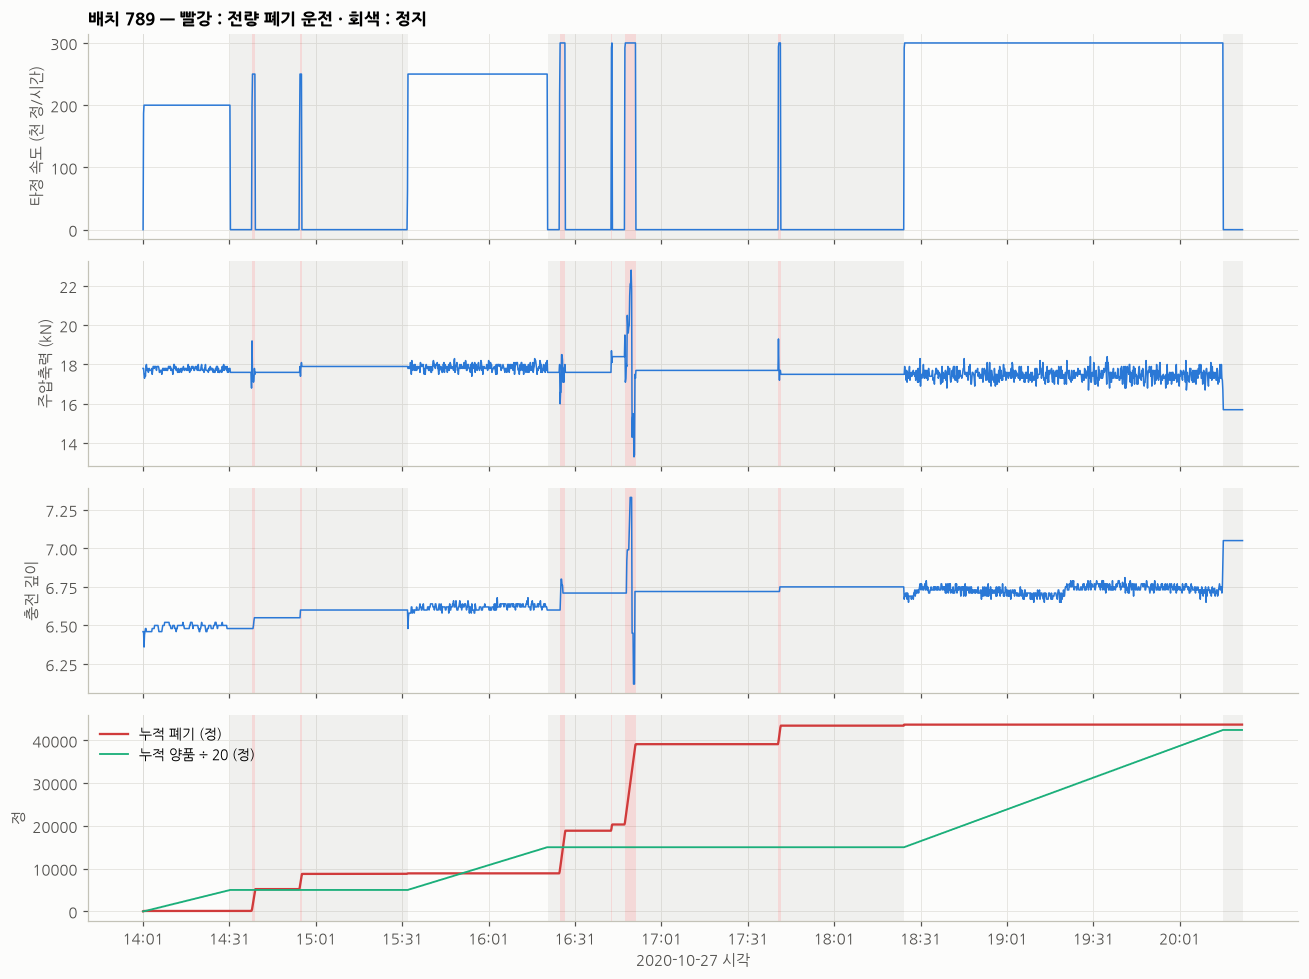

In [10]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
x = u["min"]
for ax, col, lab in zip(axes[:3], ["tbl_speed", "main_comp", "tbl_fill"], ["타정 속도 (천 정/시간)", "주압축력 (kN)", "충전 깊이"]):
    ax.plot(x, u[col], lw=1, color="#2a78d6"); ax.set_ylabel(lab)
cw, cp = u.waste.astype(float).copy(), (u.produced * 1000 / 20).astype(float)
cw.iloc[-1] = cp.iloc[-1] = np.nan                      # 배치 끝 계수기 초기화 샘플은 그리지 않음
axes[3].plot(x, cw, lw=1.5, color="#d03b3b", label="누적 폐기 (정)")
axes[3].plot(x, cp, lw=1.2, color="#1baf7a", label="누적 양품 ÷ 20 (정)")
axes[3].legend(loc="upper left", fontsize=9); axes[3].set_ylabel("정")
for ax in axes:
    for _, r in rej.iterrows():
        ax.axvspan(r.시작, r.시작 + r.길이_분, color="#d03b3b", alpha=0.18, lw=0)
    for a, b in _segments((~run).to_numpy()):
        ax.axvspan(a / 6, b / 6, color="#898781", alpha=0.10, lw=0)
ticks = np.arange(0, x.max() + 1, 30)
axes[3].set_xticks(ticks); axes[3].set_xticklabels([clock(t) for t in ticks])
axes[3].set_xlabel("2020-10-27 시각")
axes[0].set_title("배치 789 — 빨강 : 전량 폐기 운전 · 회색 : 정지", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**[확인]** 배치는 9개 운전 구간과 그 사이 정지로 나뉩니다.
- **양품 운전 3개** (14:01 속도 200 · 30분, 15:32 속도 250 · 49분, 18:25 속도 300 · 111분) : 폐기가 거의 0입니다.
- **전량 폐기 운전 6개** (14:38, 14:55, 16:25, 16:43, 16:48, 17:41) : 재시작 첫 샘플부터 생산량 전부(10초당 약 700~900정)가 폐기로 빠지고, 0.3~3.8분 만에 다시 멈췄습니다. **기록 폐기의 93%**가 여기서 나왔습니다.
- 속도는 이 구간 동안 200 → 250(14:38) → 300(16:25)으로 올라갔습니다. 첫 250 운전과 첫 300 운전이 모두 전량 폐기 운전입니다.

**[추정]** 셋업을 배치 시작 전에 하지 않고(셋업 0.5분), **생산 도중에 속도를 올리며 정지 → 시험 운전(전량 배출) → 정지를 되풀이**한 모습입니다. 평소 셋업은 속도 120에서 하지만 여기서는 250~300에서 했으므로, 같은 시간을 시험 운전해도 폐기되는 정제가 2~2.5배입니다.

### 4.1 전량 폐기는 품질 신호 때문이었나? — 운전 단위 정확 순열검정

폐기가 무게 이탈(SREL)이나 압축력 이상 같은 **품질 신호** 때문이라면, 전량 폐기 운전에서 그 신호가 달라야 합니다. 10초 샘플은 서로 독립이 아니므로 **운전 하나를 한 단위**로 묶습니다. 9개 운전(전량 폐기 6 · 양품 3)을 나누는 모든 경우(84가지)에서 두 집단 평균 차이의 정확한 귀무분포를 만들어 비교합니다.

In [11]:
def exact_perm(values, labels):
    """양측 정확 순열검정 : 라벨을 가능한 모든 방식으로 재배치"""
    v = np.asarray(values, float); lab = np.asarray(labels, bool)
    obs = v[lab].mean() - v[~lab].mean()
    diffs = [v[list(c)].mean() - np.delete(v, list(c)).mean() for c in itertools.combinations(range(len(v)), lab.sum())]
    return obs, np.mean(np.abs(diffs) >= abs(obs) - 1e-12), len(diffs)

lab = (R.유형 == "전량 폐기").to_numpy()
out = []
for col in ["주압축력", "충전깊이", "실린더", "SREL", "배출력", "속도", "급분속도"]:
    obs, p, n = exact_perm(R[col], lab)
    out.append({"신호": col, "전량 폐기 운전 평균": R.loc[lab, col].mean(), "양품 운전 평균": R.loc[~lab, col].mean(),
                "차이": obs, "정확 p (양측)": p, "경우의 수": n})
display(pd.DataFrame(out).set_index("신호").round(3))

,전량 폐기 운전 평균,양품 운전 평균,차이,정확 p (양측),경우의 수
신호,,,,,
주압축력,17.883,17.700,0.183,0.440,84
충전깊이,6.660,6.617,0.043,0.690,84
실린더,1.700,1.707,-0.007,0.333,84
SREL,3.133,2.833,0.300,0.262,84
배출력,538.667,561.000,-22.333,0.167,84
속도,282.683,250.000,32.683,0.345,84
급분속도,73.333,66.667,6.667,0.524,84


**[통계]** 압축력·충전 깊이·실린더 높이·무게 신호(SREL)·배출력 모두 전량 폐기 운전과 양품 운전 사이에 유의한 차이가 없습니다. 신호 수준으로 보면 두 운전은 같은 정제를 만들고 있었습니다. 운전이 3개·6개뿐이라 검정력은 낮으므로, '차이가 없다'를 증명한 것은 아니고 **'차이가 있다는 근거가 없다'**는 뜻입니다.

**[추정]** 폐기는 정제 품질 신호가 아니라 **재시작 직후 배출 게이트를 폐기 쪽으로 둔 운전 방식**(시험 운전, 또는 2호기의 재시작 시 자동 배출 설정)에서 나왔을 가능성이 큽니다. → 확인할 기록 : 2호기 HMI 이벤트·알람 로그의 해당 6개 시각(14:38 · 14:55 · 16:25 · 16:43 · 16:48 · 17:41), 배출 게이트(정상/폐기) 전환 기록.

### 4.2 789의 정지 한 번은 평소 정지와 얼마나 다른가

제품 17 모든 배치의 본생산 중 1분 이상 정지를 사건 단위로 모아, 정지 1분 전 ~ 재시작 5분 후 사이에 쌓인 폐기를 비교합니다.

In [12]:
def stop_events(v):
    v = v.reset_index(drop=True)
    w = v.waste.to_numpy().astype(float)
    dw = np.r_[0, np.clip(np.diff(w), 0, None)]; dw[-1] = 0
    prod = np.flatnonzero(v.produced.to_numpy() > 0)
    s0 = prod[0] if len(prod) else len(v)
    ev = []
    for a, b in _segments(v.tbl_speed.to_numpy() == 0):
        if b - a < 6 or a < s0 or b >= len(v) - 1:   # 1분 이상, 본생산 중, 배치 끝 정지 제외
            continue
        ev.append({"정지 시작(분)": a / 6, "정지 길이(분)": (b - a) / 6, "정지 전후 폐기": dw[max(a - 6, 0):b + 30].sum()})
    return pd.DataFrame(ev)

EV = pd.concat([stop_events(v).assign(batch=b) for b, v in ts.groupby("batch")], ignore_index=True)
EV = EV.dropna(subset=["정지 전후 폐기"])
e789, eref = EV[EV.batch == B], EV[EV.batch != B]
mw = stats.mannwhitneyu(e789["정지 전후 폐기"], eref["정지 전후 폐기"], alternative="greater")
print(f"참조 정지 {len(eref)}건 : 정지 전후 폐기 중앙값 {eref['정지 전후 폐기'].median():.0f}정 · 90% {eref['정지 전후 폐기'].quantile(.9):,.0f} · 99% {eref['정지 전후 폐기'].quantile(.99):,.0f}")
print(f"789 정지 {len(e789)}건 : 중앙값 {e789['정지 전후 폐기'].median():,.0f}정 · 맨-휘트니 U 단측 p = {mw.pvalue:.1e} · "
      f"클리프 δ = {cliffs_delta(e789['정지 전후 폐기'], eref['정지 전후 폐기']):.2f}")
e789 = e789.assign(시각=e789["정지 시작(분)"].map(clock),
                   참조_분위=e789["정지 전후 폐기"].map(lambda v: (eref["정지 전후 폐기"] < v).mean()))
display(e789.drop(columns="batch").round(3))

참조 정지 508건 : 정지 전후 폐기 중앙값 70정 · 90% 3,300 · 99% 6,217
789 정지 8건 : 중앙값 8,278정 · 맨-휘트니 U 단측 p = 1.6e-06 · 클리프 δ = 0.96


,정지 시작(분),정지 길이(분),정지 전후 폐기,시각,참조_분위
325,30.333,7.500,5118.0,14:31,0.972
326,39.000,15.333,8313.0,14:40,0.996
327,55.167,36.667,3684.0,14:56,0.921
328,140.500,4.167,9987.0,16:21,1.000
329,146.667,16.000,8244.0,16:27,0.996
330,163.000,4.333,20259.0,16:44,1.000
331,171.167,49.500,9453.0,16:52,1.000
332,221.500,42.833,4572.0,17:42,0.951


**[통계]** 평소 정지 한 번에 따라오는 폐기는 중앙값 수십 정이고 99%가 약 6천 정 아래입니다. 789의 정지 8건은 모두 참조 상위 8% 안이고 5건은 상위 1% 안이며, 집단으로도 확연히 큽니다(맨-휘트니 단측 p ≈ 2×10⁻⁶, 클리프 δ ≈ 0.96). **789의 문제는 정지 횟수(9회, 경험적 p 0.16)보다 정지 한 번에 따라온 폐기량**입니다.

---
## 5. 기록되지 않은 손실 — 960,000정의 질량 수지

시계열의 양품 계수기(`produced`, 천 정 단위 누적)와 폐기 계수기(`waste`, 누적)로 이론 생산량을 나눠 봅니다.

이론 생산량 = **계수된 양품** + **계수된 폐기** + **어느 계수기에도 잡히지 않은 양**

In [13]:
def balance(b):
    v = ts[ts.batch == b]
    size = df.loc[b, "size"]
    good_cnt = v.produced.max() * 1000
    waste = v.waste.max()
    final = size * df.loc[b, "batch_yield"] / 100
    return {"이론 생산량": size, "계수 양품": good_cnt, "계수 폐기": waste, "미계수": size - good_cnt - waste,
            "최종 양품(배치 수율)": final, "계수 완전": good_cnt >= final - 1000}

BAL = pd.DataFrame({b: balance(b) for b in ts.batch.unique()}).T
BAL[["이론 생산량", "계수 양품", "계수 폐기", "미계수", "최종 양품(배치 수율)"]] = BAL[["이론 생산량", "계수 양품", "계수 폐기", "미계수", "최종 양품(배치 수율)"]].astype(float)
BAL["계수 완전"] = BAL["계수 완전"].astype(bool)
b789 = BAL.loc[B]
bref = BAL.drop(B)
print(f"계수 완전성 : 참조 {len(bref)}개 중 {bref['계수 완전'].sum()}개만 '계수 양품 ≥ 최종 양품' (나머지는 시계열이 배치 일부만 담음) · 789 = {bool(b789['계수 완전'])}")
bref = bref[bref["계수 완전"]]
cols = ["이론 생산량", "계수 양품", "계수 폐기", "미계수", "최종 양품(배치 수율)"]
show = pd.DataFrame({"789": b789[cols], "제품 17 중앙값": bref[cols].median()})
show["789 − 중앙값"] = show["789"] - show["제품 17 중앙값"]
display(show.astype(float).round(0))
print(f"미계수 : 789 {b789['미계수']:,.0f}정 = 이론의 {b789['미계수'] / b789['이론 생산량']:.1%} · "
      f"참조 중앙값 {bref['미계수'].median():,.0f}정 · 참조 최대 {bref['미계수'].max():,.0f}정 · "
      f"경험적 p = {emp_p(bref['미계수'], b789['미계수']):.4f}")

계수 완전성 : 참조 206개 중 158개만 '계수 양품 ≥ 최종 양품' (나머지는 시계열이 배치 일부만 담음) · 789 = True


,789,제품 17 중앙값,789 − 중앙값
이론 생산량,960000.0,960000.0,0.0
계수 양품,849000.0,950000.0,-101000.0
계수 폐기,43707.0,6510.0,37198.0
미계수,67293.0,2904.0,64389.0
최종 양품(배치 수율),844541.0,947765.0,-103224.0


미계수 : 789 67,293정 = 이론의 7.0% · 참조 중앙값 2,904정 · 참조 최대 12,940정 · 경험적 p = 0.0126


In [14]:
# 고속이 미계수 손실을 늘리는가? — 제품 17 이력 안에서 가능한 비교 (속도 120 vs 160, 계수 완전한 배치만)
H = bref.join(df[["tbl_speed_mean"]])
H["속도"] = H.tbl_speed_mean.round(-1)
a, b = H.loc[H.속도 == 120, "미계수"], H.loc[H.속도 == 160, "미계수"]
mw = stats.mannwhitneyu(b, a, alternative="two-sided")
rho = stats.spearmanr(H.tbl_speed_mean, H.미계수)
print(f"미계수 중앙값 : 속도 120 배치 {a.median():,.0f}정 (n={len(a)}) · 속도 160 배치 {b.median():,.0f}정 (n={len(b)}) · "
      f"맨-휘트니 p = {mw.pvalue:.3f} · 클리프 δ(160 vs 120) = {cliffs_delta(b, a):+.2f}")
print(f"스피어만 ρ(속도, 미계수) = {rho.statistic:+.3f}, p = {rho.pvalue:.3f}")

미계수 중앙값 : 속도 120 배치 1,959정 (n=121) · 속도 160 배치 5,828정 (n=29) · 맨-휘트니 p = 0.000 · 클리프 δ(160 vs 120) = +0.62
스피어만 ρ(속도, 미계수) = +0.305, p = 0.000


**계수 완전성 점검** : 계수된 양품은 최종 양품보다 적을 수 없습니다(계수 뒤에 줄어들 수만 있음). 그런데 참조 배치 중 일부는 계수 양품이 최종 양품보다 수십만 정 적습니다 — 시계열이 배치의 일부 구간만 담은 경우입니다. 이런 배치는 미계수 손실이 부풀려지므로 참조에서 뺐습니다. 789는 계수 양품 849,000 ≥ 최종 양품 844,541로 완전합니다.

**[확인]** 이론 960,000정 중 계수된 양품 849,000정, 계수된 폐기 43,707정이고, **67,293정(7.0%)은 어느 계수기에도 잡히지 않았습니다.** 계수가 완전한 참조 158개의 최대(12,940정)보다 5배 크고 중앙값의 20배가 넘습니다. 이 손실이 기록 폐기보다 1.5배 큽니다.

배치 RCA의 '미기록 손실' 71,752정은 이 67,293정에 계수 이후 줄어든 4,459정(계수 양품 849,000 − 최종 양품 844,541; IPC 시료·제진 등)을 더한 값입니다.

**[통계]** 제품 17 이력에서 속도 160 배치는 120 배치보다 미계수 손실이 약 3배이고(맨-휘트니 p < 0.001, 클리프 δ ≈ +0.6), 속도와 미계수 손실의 순위상관도 양(ρ ≈ +0.3)입니다. **속도가 오를수록 계수기 밖 손실이 커지는 관계가 이력 안에서 확인됩니다.** 789의 200~300은 이력(90~160) 밖이라 크기를 외삽할 수는 없지만, 방향은 789의 극단적 미계수 손실과 맞습니다.

**[추정]** 고속과 함께 커진다는 것까지는 데이터가 말해 주지만, 정제가 *어디로* 사라졌는지는 가를 수 없습니다. 가능한 설명과 확인 방법은 다음과 같습니다.

| 가능한 설명 | 맞다면 보일 것 | 확인할 기록 |
|---|---|---|
| 2호기의 폐기 배출 경로 일부가 폐기 계수기를 거치지 않음 | 전량 폐기 운전 시간과 미계수 양이 비례 | 2호기 폐기 계수 위치·배출 경로 |
| 배치 종료 시 호퍼·피더 잔량 분말 폐기 (고속에서 체류량 증가) | 분말 칭량 기록에서 잔량 확인 | 배치 기록서의 원료 투입량·잔량·회수량 |
| 고속 운전 중 분말 비산·누설 | 집진기 회수량 증가 | 집진기 회수 기록 |
| 2호기 양품 계수기 보정 차이 | 양품 무게 환산과 계수 차이 | 완제품 총중량 ÷ 평균 정제 무게 |

---
## 6. 경쟁 가설 점검 — 원인인가, 결과인가, 우연인가

### 6.1 배출력 과다는 독립 원인인가?

배출력 563은 이력 최대(483)를 넘습니다. 하지만 배출력은 압축력이 높으면 함께 올라갑니다. 참조 배치에서 '배출력 ~ 주압축력' 회귀를 세우고, 789의 압축력에서 예측되는 배출력과 비교합니다.

배출력 = -13.8 + 32.56 × 주압축력 (r = 0.37, n = 206)
789 : 주압축력 17.63 → 예측 배출력 560 (95% 예측구간 375 ~ 745) · 실제 563


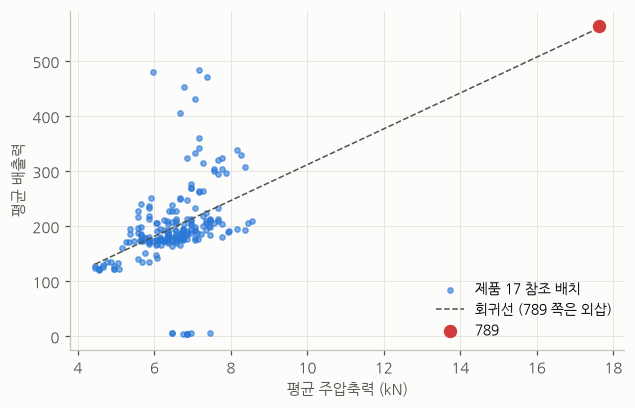

In [15]:
r17 = dp.drop(B)[["main_CompForce mean", "ejection_mean"]].dropna()
lr = stats.linregress(r17["main_CompForce mean"], r17.ejection_mean)
x0 = T["main_CompForce mean"]
n = len(r17); xb = r17["main_CompForce mean"].mean(); sxx = ((r17["main_CompForce mean"] - xb) ** 2).sum()
resid = r17.ejection_mean - (lr.intercept + lr.slope * r17["main_CompForce mean"])
se_pred = np.sqrt((resid ** 2).sum() / (n - 2) * (1 + 1 / n + (x0 - xb) ** 2 / sxx))
pred = lr.intercept + lr.slope * x0
tq = stats.t.ppf(0.975, n - 2)
print(f"배출력 = {lr.intercept:.1f} + {lr.slope:.2f} × 주압축력 (r = {lr.rvalue:.2f}, n = {n})")
print(f"789 : 주압축력 {x0:.2f} → 예측 배출력 {pred:.0f} (95% 예측구간 {pred - tq * se_pred:.0f} ~ {pred + tq * se_pred:.0f}) · 실제 {T.ejection_mean:.0f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(r17["main_CompForce mean"], r17.ejection_mean, s=12, color="#2a78d6", alpha=0.6, label="제품 17 참조 배치")
xs = np.linspace(r17["main_CompForce mean"].min(), x0, 50)
ax.plot(xs, lr.intercept + lr.slope * xs, color="#52514e", lw=1, ls="--", label="회귀선 (789 쪽은 외삽)")
ax.scatter([x0], [T.ejection_mean], s=60, color="#d03b3b", label="789", zorder=3)
ax.set_xlabel("평균 주압축력 (kN)"); ax.set_ylabel("평균 배출력"); ax.legend(fontsize=9); plt.show()

**[통계]** 789의 배출력은 압축력만으로 예측되는 값과 거의 같습니다 (예측구간 안). 배출력 과다(RCA의 MAC-3)는 **높은 압축력의 결과**이지 별도 원인이라는 근거가 없습니다. 789의 압축력은 이력 범위 밖이라 회귀선은 **외삽**이며, 결론은 '독립 원인 근거 없음'까지입니다.

### 6.2 고속 자체가 수율을 떨어뜨리나?

- 배치 안 : 마지막 양품 운전(18:25~, 속도 300, 111분)의 폐기는 첫 샘플 237정 외 0입니다 (4장 표) → **[확인]** 고속 정상 운전에서는 기록 폐기가 생기지 않았습니다.
- 이력 : 제품 17에서 속도 160으로 돈 배치와 120 배치의 수율을 비교합니다.

In [16]:
Y = df[(df.code == CODE) & (df.index != B)].copy()
Y["속도"] = Y.tbl_speed_mean.round(-1)
a, b = Y.loc[Y.속도 == 120, "batch_yield"], Y.loc[Y.속도 == 160, "batch_yield"]
mw = stats.mannwhitneyu(b, a, alternative="two-sided")
print(f"수율 중앙값 : 속도 120 {a.median():.2f}% (n={len(a)}) · 속도 160 {b.median():.2f}% (n={len(b)}) · "
      f"맨-휘트니 p = {mw.pvalue:.3f} · 클리프 δ(160 vs 120) = {cliffs_delta(b, a):+.2f}")
print(f"속도 160 배치의 생산 시기 : {dates.loc[Y.index[Y.속도 == 160], 'start_dt'].min():%Y-%m} ~ {dates.loc[Y.index[Y.속도 == 160], 'start_dt'].max():%Y-%m}")

수율 중앙값 : 속도 120 98.86% (n=157) · 속도 160 98.51% (n=36) · 맨-휘트니 p = 0.012 · 클리프 δ(160 vs 120) = -0.27
속도 160 배치의 생산 시기 : 2019-05 ~ 2021-02


**[통계]** 속도 160 배치는 120 배치보다 수율 중앙값이 약 0.35%p 낮고 유의합니다(클리프 δ ≈ −0.27). 5장에서 본 대로 이 차이의 상당 부분은 미계수 손실 증가와 같은 방향입니다. 다만 크기는 789의 10.8%p 저하와 비교할 수 없고, 160 배치의 생산 시기가 다양해 시기 효과가 섞여 있을 수 있습니다.

정리하면 **고속은 '운전 중 기록 폐기'를 늘리지는 않았지만(배치 안 111분 고속 무폐기), '계수기 밖 손실'과는 이력에서 함께 움직입니다.** 789 직후 제품 17 캠페인(802~)은 속도 160으로 돌았습니다. 789가 고속 운전 시험이었는지는 데이터로 알 수 없습니다 → 확인할 기록 : 2020년 10월 변경 관리(Change Control)·공정 시험 계획서.

### 6.3 API 로트 197

789는 API 로트 197을 쓴 첫 배치입니다 (같은 캠페인의 783~788은 196·192). 로트 197을 쓴 배치는 전체에서 2개뿐입니다.

In [17]:
J = judged(DATA).join(df[["api_code", "api_batch", "startup_waste", "total_waste"]])
A3 = J[J.api_code == 3].copy()
A3["저수율"] = A3.robust_z < -2
A3["로트 197"] = A3.api_batch == 197
tab2 = pd.crosstab(A3["로트 197"], A3["저수율"])
display(tab2)
print("Fisher 정확검정 (단측 : 로트 197이면 저수율이 많다) p =", round(stats.fisher_exact(tab2.values, alternative="greater")[1], 4))
display(J.loc[J.api_batch == 197, ["code", "batch_yield", "robust_z", "판정"]])

lots = df[df.api_code == 3].groupby("api_batch")[["api_water", "api_total_impurities", "api_content", "api_ps01", "api_ps05", "api_ps09"]].first()
pct = {c: (lots[c] <= lots.loc[197, c]).mean() for c in lots.columns}
display(pd.DataFrame({"로트 197": lots.loc[197], "전 로트 중 백분위": pd.Series(pct)}).round(3))
p15 = df[df.code == 15]
print(f"799(제품 15) 셋업 폐기 {df.loc[799, 'startup_waste']:,}정 = 제품 15 중 상위 {1 - (p15.startup_waste < df.loc[799, 'startup_waste']).mean():.0%}")

저수율,False,True
로트 197,,
False,438,41
True,0,2


Fisher 정확검정 (단측 : 로트 197이면 저수율이 많다) p = 0.0078


,code,batch_yield,robust_z,판정
batch,,,,
789,17,87.973,-15.394931,수율 일탈(하한 미달)
799,15,95.640,-3.228577,수율 일탈(하한 미달)


,로트 197,전 로트 중 백분위
api_water,1.90,0.792
api_total_impurities,0.29,0.192
api_content,93.90,0.246
api_ps01,4.00,0.746
api_ps05,47.00,0.538
api_ps09,165.00,0.415


799(제품 15) 셋업 폐기 29,032정 = 제품 15 중 상위 2%


**[통계]** 로트 197을 쓴 두 배치(789, 제품 15의 799)가 모두 수율 일탈입니다. 우연이라면 일어나기 어려운 조합입니다 (Fisher p ≈ 0.008). 그러나
- 로트 197의 물성(수분·불순물·함량·입도)은 전 로트 중 19~79 백분위로 평범합니다.
- 789의 손실은 4~5장에서 본 운전 사건(전량 폐기 운전·미계수)으로 거의 다 설명됩니다.
- 799(제품 15)도 셋업 폐기가 제품 15 상위 2%로 많았습니다. 두 배치 모두 셋업·재시작 쪽 손실이 컸다는 점은 공통입니다.
- 표본이 2개라 해석에 한계가 있습니다.

→ **로트 197은 789의 주원인이라는 근거는 없지만, 독립적으로 확인할 신호**입니다. 확인할 기록 : 로트 197 성적서(CoA)의 시험 외 항목(유동성·벌크 밀도), 799의 조사 기록.

### 6.4 품질 영향 — 용출

용출 평균 85.33%는 제품 17 하위 약 5%입니다. 압축력이 높으면 용출이 느려질 수 있어 확인합니다.

In [18]:
p17 = df[(df.code == CODE) & (df.index != B)]
lo = ((p17.dissolution_av <= df.loc[B, "dissolution_av"]).sum() + 1) / (p17.dissolution_av.notna().sum() + 1)
rho = stats.spearmanr(p17["main_CompForce mean"], p17.dissolution_av, nan_policy="omit")
print(f"789 용출 평균 {df.loc[B, 'dissolution_av']:.2f}% · 제품 17 중앙값 {p17.dissolution_av.median():.2f}% · 하위 단측 경험적 p = {lo:.3f}")
print(f"제품 17 이력 : 스피어만 ρ(주압축력, 용출) = {rho.statistic:+.2f}, p = {rho.pvalue:.4f}")

789 용출 평균 85.33% · 제품 17 중앙값 89.17% · 하위 단측 경험적 p = 0.048
제품 17 이력 : 스피어만 ρ(주압축력, 용출) = +0.26, p = 0.0002


**[통계]** 789의 용출은 낮은 편이지만, 이력에서는 압축력이 높을수록 오히려 용출이 **높은** 경향이라 '고압축 → 용출 저하'로 설명되지 않습니다. 원인은 미확인이고 수율과는 별개의 **품질 확인 항목**으로 남깁니다 (출하 시험 기록 확인).

### 6.5 그 밖의 가설

| 가설 | 789 상태 | 판단 |
|---|---|---|
| 야간·주말 작업 (RCA MAN-1·2) | 화요일 14:01 시작, 20:23 종료 | **[확인]** 해당 없음 |
| 원료 물성 이상 (RCA MAT-1·2) | 1장 스크리닝에서 원료 변수 0개 | **[통계]** 근거 없음 |
| 캠페인 첫 배치 효과 (RCA MET-1·2) | 실제 시간 순서로는 캠페인의 3번째 (783·784 다음), 다만 2호기에서는 첫 배치 | **[추정]** '2호기 첫 배치 + 셋업 생략'이 같은 역할 |
| 계절 (RCA ENV-1) | 10월, 같은 시기 784~788 정상 | **[확인]** 같은 날 같은 제품이 정상 → 환경 공통 원인 아님 |

---
## 7. 손실 귀속과 반사실 수율

789의 손실 115,459정을 구성 요소로 나누고, 각 요소를 제품 17 참조 중앙값으로 되돌렸을 때의 수율을 계산합니다. **단순 산술**이라 요소 사이 상호작용은 반영하지 않습니다.

In [19]:
size = df.loc[B, "size"]
good = size * T.batch_yield / 100
ref_setup = df.loc[ref.index, "startup_waste"].median()
rej_w = rej.폐기.sum()
other_w = u.waste.max() - rej_w
unc = b789["미계수"]; ref_unc = bref["미계수"].median()
post = b789["계수 양품"] - b789["최종 양품(배치 수율)"]

parts = pd.DataFrame([
    ("전량 폐기 운전 6번 (재시작 직후)", rej_w, ref_setup, "평소 셋업 폐기 중앙값으로 대체"),
    ("그 밖의 기록 폐기", other_w, 0, "—"),
    ("미계수 손실", unc, ref_unc, "참조 중앙값으로 대체"),
    ("계수 후 감소 (IPC 시료 등)", post, (bref["계수 양품"] - bref["최종 양품(배치 수율)"]).median(), "참조 중앙값"),
], columns=["구성 요소", "789 (정)", "참조 수준 (정)", "반사실 가정"])
parts["수율 영향 (%p)"] = -parts["789 (정)"] / size * 100
display(parts.round(1))
print(f"구성 요소 합 {parts['789 (정)'].sum():,.0f}정 = 손실 {size - good:,.0f}정")

def cf(*names):
    g = good + sum(parts.set_index("구성 요소").loc[n, "789 (정)"] - parts.set_index("구성 요소").loc[n, "참조 수준 (정)"] for n in names)
    return g / size * 100

for label, names in [("전량 폐기 운전 → 평소 셋업 수준", ["전량 폐기 운전 6번 (재시작 직후)"]),
                     ("미계수 손실 → 참조 중앙값", ["미계수 손실"]),
                     ("둘 다", ["전량 폐기 운전 6번 (재시작 직후)", "미계수 손실"])]:
    y = cf(*names)
    print(f"{label:28s} → 수율 {y:.2f}%  ({'정상' if y >= spec.loc[CODE, '경고_하한'] else '이상' if y >= spec.loc[CODE, '일탈_하한'] else '일탈'})")

,구성 요소,789 (정),참조 수준 (정),반사실 가정,수율 영향 (%p)
0,전량 폐기 운전 6번 (재시작 직후),40551.0,5157.0,평소 셋업 폐기 중앙값으로 대체,-4.2
1,그 밖의 기록 폐기,3156.0,0.0,—,-0.3
2,미계수 손실,67293.0,2904.0,참조 중앙값으로 대체,-7.0
3,계수 후 감소 (IPC 시료 등),4459.2,2048.0,참조 중앙값,-0.5


구성 요소 합 115,459정 = 손실 115,459정
전량 폐기 운전 → 평소 셋업 수준          → 수율 91.66%  (일탈)
미계수 손실 → 참조 중앙값              → 수율 94.68%  (일탈)
둘 다                          → 수율 98.37%  (정상)


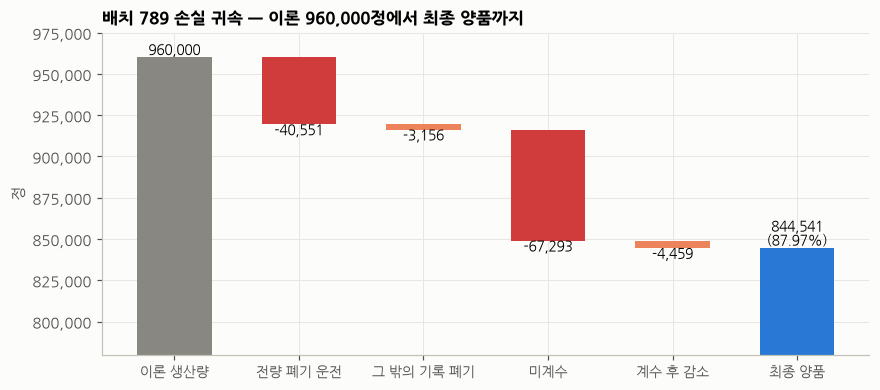

In [20]:
steps = [("이론 생산량", size), ("전량 폐기 운전", -rej_w), ("그 밖의 기록 폐기", -other_w),
         ("미계수", -unc), ("계수 후 감소", -post)]
fig, ax = plt.subplots(figsize=(9, 3.8))
level = 0
for i, (lab, v) in enumerate(steps):
    if i == 0:
        ax.bar(i, v, color="#898781", width=0.6); level = v
    else:
        ax.bar(i, v, bottom=level, color="#d03b3b" if v < -10000 else "#ec835a", width=0.6); level += v
    ax.text(i, level + 2000 if i == 0 else level - 6000, f"{v:+,.0f}" if i else f"{v:,.0f}", ha="center", fontsize=9)
ax.bar(len(steps), level, color="#2a78d6", width=0.6); ax.text(len(steps), level + 2000, f"{level:,.0f}\n({level / size:.2%})", ha="center", fontsize=9)
ax.set_xticks(range(len(steps) + 1)); ax.set_xticklabels([s for s, _ in steps] + ["최종 양품"], fontsize=9)
ax.set_ylim(780000, 975000); ax.set_ylabel("정")
ax.set_title("배치 789 손실 귀속 — 이론 960,000정에서 최종 양품까지", loc="left", fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.show()

**[확인]** 789의 수율 저하는 거의 전부 두 요소입니다. **미계수 손실 6.7만 정(−7.0%p)**과 **재시작 직후 전량 폐기 운전 4.1만 정(−4.2%p)**입니다. 하나만 되돌려서는 여전히 일탈이고, **둘 다** 참조 수준으로 되돌려야 수율이 약 98.4%로 정상 범위에 들어옵니다. 두 손실 모두를 막아야 했다는 뜻입니다.

---
## 8. 결론 — 배치별 RCA와 무엇이 다른가

| | 배치별 RCA 노트북 | 이 노트북 |
|---|---|---|
| 결론 문장 | 재시작 후 안정화 확인 절차·설정값 이중 확인 절차가 **없다** | **2호기**에서 이력 밖 조건(속도 300·17.6 kN)으로 **셋업 없이** 시작, 속도를 올리며 **재시작 직후 전량 폐기 운전 6번**(4.1만 정) + **미계수 6.7만 정**(이력에서 고속과 함께 증가) |
| 손실 귀속 | 없음 (가설 채택 여부만) | 요소별 정 단위 귀속, 반사실 수율 98.4% |
| 원인·결과 구분 | 배출력 과다(MAC-3)를 관찰 가설로 둠 | 배출력은 압축력의 결과 (회귀 예측구간) |
| 새로 나온 신호 | — | 같은 제품 동시 생산(유일), API 로트 197(Fisher p 0.008), 용출 하위 5% |
| 다음 행동 | SOP 보완 | 아래 기록을 **시각까지 특정**해 확인 |

### 확인할 기록 (우선순위 순)

1. **2호기 사용 경위** : 10/27 14:01 제품 17을 평소와 다른 타정기에서 생산한 이유 — 생산 계획, 변경 관리(Change Control), 공정 시험 계획서 (속도 상향 시험이었는지)
2. **2호기 HMI 이벤트·알람 로그** : 전량 폐기 운전 시작 시각 14:38 · 14:55 · 16:25 · 16:43 · 16:48 · 17:41 전후의 정지 사유, 배출 게이트 전환, 설정 변경(속도·충전 깊이)
3. **미계수 6.7만 정** : 배치 기록서의 원료 투입·잔량·회수량, 2호기 폐기 배출 경로와 계수 위치, 집진기 회수량
4. **셋업 기록** : 2호기 셋업을 언제 어디서 했는지 (시계열에는 셋업 0.5분)
5. **API 로트 197** : 성적서의 유동성·벌크 밀도, 제품 15 배치 799 조사 기록
6. **품질** : 789 출하 시험의 용출 결과와 판정

### 서비스(에이전트)에 주는 시사점

- 템플릿 RCA는 '가설 목록 → 검정 → 기준 부재' 구조라 결론이 일반론으로 수렴합니다. 789 같은 극단 배치에서는 **① 전 변수 스크리닝 → ② 시간 구조(동시 생산·운전 구간) → ③ 손실 귀속 → ④ 경쟁 가설 배제** 순서가 훨씬 구체적인 결론을 냅니다.
- 이 순서는 대부분 결정론적 계산이라, RCA 에이전트에 **'정밀 분석 모드'** 도구로 넣을 수 있습니다 (스크리닝 표, 동시 생산 검사, 전량 폐기 운전 탐지, 질량 수지).